# Gradient Descent: Full Datasets, Single Examples, and Mini-batches

## 1. Introduction and learning objectives

An objective describes which parameters are desirable; an optimizer describes how to search for them. A direct least-squares formula is convenient for a small linear problem, but many later models have no comparable closed form. Gradient descent repeatedly uses local slope information to improve a parameter vector.

You will derive its update rule, examine exactly when a step decreases a simple quadratic, distinguish batch, stochastic, and mini-batch gradients, and compare them with fair computational budgets. You will implement all three variants yourself and investigate feature scaling, random order, monitoring, and stopping.

Recommended prerequisite: [Linear Regression](linear-regression.ipynb). This notebook restates the required notation and calculus, so you can work independently if you already understand derivatives, vector dot products, and squared error. No optimizer is supplied in executable code.

### Working environment

Run this setup cell before working on the implementation challenges. It imports numerical and plotting tools, without defining any exercise solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 2.01 — Separate a model from an optimizer

**Type:** Conceptual · **Answer:** Markdown

Two people minimize the same linear-regression loss. One solves an equation; the other repeatedly changes parameters. Identify what is shared and what differs. Explain why switching optimizers alone does not make the prediction function nonlinear.

**Expected outcome:** A distinction between the model family, objective, and search procedure.

**Your response to Exercise 2.01**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 2. Prerequisites and mathematical foundations

### A gradient is local information

Write all $p$ adjustable parameters as $\theta\in\mathbb R^p$. In linear regression, $\theta=(b,w_1,\ldots,w_d)^T$ and $p=d+1$. The function $J(\theta)$ is a scalar objective. Its gradient $g=\nabla_\theta J$ is the vector of partial derivatives, each changing one parameter while the others stay fixed.

For a sufficiently small change vector $\Delta$, differentiability gives a first-order approximation

$$
J(\theta+\Delta)\approx J(\theta)+g^T\Delta.
$$

The Euclidean length of a vector $v$ is $\lVert v\rVert_2=\sqrt{\sum_jv_j^2}$. The product $g^T\Delta=\sum_j g_j\Delta_j$ is a dot product. It estimates the change in the objective rather than its new absolute value. If $\Delta=-\alpha g$ with scalar step size $\alpha>0$, the predicted change is $-\alpha g^Tg=-\alpha\lVert g\rVert_2^2$, which is negative whenever $g\ne0$.

This motivates gradient descent, not an unlimited-step guarantee. The approximation neglects curvature. A large step can pass through a low-loss region and finish at a higher loss. The negative gradient is the direction of steepest local decrease under a Euclidean length constraint; changing feature units changes the geometry of this statement.

### Exercise 2.02 — Use a local approximation

**Type:** Numerical · **Answer:** Markdown

At a parameter vector with $J=7$ and gradient $g=(2,-1)^T$, consider $\Delta=(-0.1,0.05)^T$. Calculate the predicted objective change and approximate new value. Explain why the approximation is not an exact evaluation.

**Expected outcome:** A dot-product calculation and a statement of the small-change assumption.

**Your response to Exercise 2.02**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Objective averages and a linear-regression reminder

For $n$ observations define individual losses $\ell_i(\theta)$ and their average

$$
J(\theta)=\frac1n\sum_{i=1}^n\ell_i(\theta),
\qquad
\nabla J(\theta)=\frac1n\sum_{i=1}^n\nabla\ell_i(\theta).
$$

The index $i$ identifies an observation. Differentiating an average gives the average of derivatives because differentiation is linear.

For linear regression let $X\in\mathbb R^{n\times d}$ contain row-wise examples, $y\in\mathbb R^n$ the targets, $w\in\mathbb R^d$ the weights, and $b$ the intercept. Predictions are $Xw+b\mathbf1_n$, where $\mathbf1_n$ is a vector of ones. Each residual is $r_i=X_{i:}w+b-y_i$; the colon means take the whole row. With $\ell_i=\frac12r_i^2$, the chain rule gives

$$
\nabla_w J=\frac1nX^Tr,\qquad
\frac{\partial J}{\partial b}=\frac1n\sum_i r_i.
$$

Here $T$ denotes transpose, $\nabla_w$ collects weight derivatives, and $\partial/\partial b$ is the intercept derivative. The factor $1/2$ in the loss cancels the square's derivative factor of two. Keep target arrays at shape `(n,)` in this notebook.

## 3. Theoretical development and worked examples

### Batch gradient descent

Let $\theta^{(t)}$ be the parameters after $t$ updates; the parenthesized superscript is a time index, not a power. Batch gradient descent evaluates every example at the same current parameters:

$$
g^{(t)}=\nabla J(\theta^{(t)}),\qquad
\theta^{(t+1)}=\theta^{(t)}-\alpha_t g^{(t)}.
$$

The positive scalar $\alpha_t$ is the learning rate at update $t$. With a constant rate, write $\alpha_t=\alpha$. Compute every gradient component before changing any parameter. Updating one weight and then computing another gradient at that new weight produces a different procedure.

**Worked example.** For scalar $\theta$, let $J(\theta)=\frac12(\theta-2)^2$. Its derivative is $\theta-2$. Starting at zero with $\alpha=0.3$, the first gradient is $-2$, so the first new parameter is $0-0.3(-2)=0.6$. The next gradient is $-1.4$, giving $0.6-0.3(-1.4)=1.02$. The gradient magnitude shrinks as the parameter approaches two.

### Exercise 2.03 — Perform two updates by hand

**Type:** Numerical · **Answer:** Markdown

For $J(\theta)=\frac12(\theta+1)^2$, start at $\theta^{(0)}=2$ and use $\alpha=1/4$. Calculate two gradients, two updated parameters, and the loss after each update.

**Expected outcome:** A table indexed by update number, with each gradient evaluated before its corresponding update.

**Your response to Exercise 2.03**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Curvature explains overshooting

Consider the scalar quadratic $J(\theta)=\frac c2(\theta-a)^2$, with curvature $c>0$ and minimizer $a$. The gradient is $c(\theta-a)$. Define the parameter error $e_t=\theta^{(t)}-a$. Subtracting $a$ from the update gives

$$
e_{t+1}=(1-\alpha c)e_t.
$$

Repeated multiplication shrinks a nonzero error exactly when $|1-\alpha c|<1$. Rearranging the two inequalities $-1<1-\alpha c<1$ yields $0<\alpha<2/c$. When $0<\alpha c<1$, the approach does not change sides. When $1<\alpha c<2$, errors alternate signs while shrinking. At $\alpha c=2$, a nonzero error alternates without shrinking; above two it grows. If the initial error is zero, it stays zero regardless of these distinctions.

For a multivariable quadratic, the **Hessian** $H$ is the matrix of second partial derivatives. Along a direction $v$ satisfying $Hv=\lambda v$, the nonnegative number $\lambda$ is that direction's curvature; such a $v$ is called an eigenvector and $\lambda$ an eigenvalue. A symmetric quadratic can be decomposed into these directions. The steepest-curvature direction sets the restriction $0<\alpha<2/\lambda_{\max}$, where $\lambda_{\max}$ is the largest positive eigenvalue.

For linear-regression half-MSE, $H=\widetilde X^T\widetilde X/n$, using the intercept-augmented matrix $\widetilde X=[\mathbf1_n\;X]$. Zero-curvature directions reflect unidentifiable parameters; their components need not approach a unique value. These quadratic statements do not promise that a general neural network has a unique optimum or that a large gradient step is safe.

### Exercise 2.04 — Explain three step-size regimes

**Type:** Mathematical · **Answer:** Markdown

For $c=4$, derive the range of constant learning rates that shrink nonzero error. Choose one learning rate for monotone approach, one for decaying oscillation, and one for divergence. Justify each choice using the error multiplier.

**Expected outcome:** Inequalities and three explained examples, rather than a rule that all smaller rates are equally efficient.

**Hint:** Study the error multiplier before choosing rates, and check the two boundary values separately.

**Your response to Exercise 2.04**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Stochastic gradient descent

Stochastic gradient descent, abbreviated SGD, samples one index $I_t$ and uses

$$
g^{(t)}=\nabla\ell_{I_t}(\theta^{(t)}).
$$

For a uniformly drawn index and parameters held fixed during sampling, the expectation, meaning the probability-weighted average over possible draws, is

$$
\mathbb E[g^{(t)}\mid\theta^{(t)}]
=\frac1n\sum_i\nabla\ell_i(\theta^{(t)})
=\nabla J(\theta^{(t)}).
$$

This **unbiasedness** concerns the gradient estimate at a fixed point. It does not say every update decreases full-data loss. A sampled observation can favor a direction that hurts others.

**Worked comparison.** Let $J(\theta)=\frac14[(\theta-1)^2+(\theta-3)^2]$. At $\theta=0$, the two individual gradients are $-1$ and $-3$, with mean $-2$. One batch update with $\alpha=0.1$ reaches $0.2$. If SGD processes the first observation then the second, it first reaches $0.1$, then uses the changed-point gradient $0.1-3=-2.9$ to reach $0.39$. Both procedures used two individual gradient evaluations, but one made one update and the other two. Averaging stale gradients is not the same as sequential updates.

### Mini-batches and epochs

A mini-batch $B_t$ is a subset or sampled collection of indices, with size $m_t=|B_t|$. Vertical bars here count its members. The update uses

$$
g^{(t)}=\frac1{m_t}\sum_{i\in B_t}\nabla\ell_i(\theta^{(t)}).
$$

Batch gradient descent uses $m_t=n$ and each example once in the estimate. SGD uses $m_t=1$. Mini-batches balance computation throughput and sampling noise. Divide by the actual batch size, including a final short batch; dividing by a preset larger size underweights that final group.

For independent uniform draws **with replacement** at a fixed $\theta$, an average of $m$ individual gradients is unbiased and its component-wise sampling variance is $1/m$ of the single-draw variance. Variance means the expected squared deviation from the mean. Sampling without replacement introduces dependence between draws and changes this variance formula.

An **epoch** is one complete pass through the training set. A common implementation shuffles the indices once per epoch and slices them into disjoint batches. This is random reshuffling, not independent sampling with replacement. At a fixed parameter vector, a random subset has an unbiased average; during an adaptive epoch, conditioning on earlier batches and updates can remove that simple guarantee for the remaining batch. Use the expectation argument only under its stated sampling conditions.

### Exercise 2.05 — Count work fairly

**Type:** Conceptual · **Answer:** Markdown

With $n=23$ observations, compare batch size 23, batch size 1, and batch size 5 over one shuffled epoch. State the number of updates, number of examples processed, and size of any last batch.

**Expected outcome:** A comparison that distinguishes update count from data passes and explains how to average the last batch.

**Your response to Exercise 2.05**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Exercise 2.06 — Show why a sampled mean can be unbiased

**Type:** Mathematical · **Answer:** Markdown

For fixed $\theta$, define $g_i=\nabla\ell_i(\theta)$. Let $I_1,\ldots,I_m$ be independent uniform draws from $\{1,\ldots,n\}$. Derive the expectation of $\frac1m\sum_{k=1}^m g_{I_k}$ using linearity of expectation. Explain what is held fixed.

**Expected outcome:** A short derivation with the sampling assumptions stated explicitly.

**Your response to Exercise 2.06**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 4. Guided exercises

### Exercise 2.07 — Compare sequential and averaged gradients

**Type:** Numerical · **Answer:** Markdown

For individual losses $\ell_1(\theta)=\frac12(\theta+2)^2$ and $\ell_2(\theta)=\frac12(\theta-4)^2$, start at $\theta=1$ and use $\alpha=0.2$. Compare one full-batch update with two SGD updates in each possible order.

**Expected outcome:** Three final parameters, plus a written explanation of order dependence. This exercise counts the same number of individual gradient evaluations.

**Your response to Exercise 2.07**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Scaling, monitoring, and stopping

Different feature units can create a long, narrow loss surface. A rate small enough for its steep direction can be frustratingly slow along a flat direction. Standardizing feature $j$ uses training mean $\mu_j$ and training standard deviation $s_j$:

$$
\mu_j=\frac1n\sum_iX_{ij},\qquad
s_j=\sqrt{\frac1n\sum_i(X_{ij}-\mu_j)^2},\qquad
X'_{ij}=(X_{ij}-\mu_j)/s_j.
$$

The prime marks transformed features. If $s_j=0$, do not divide by zero: remove the constant feature or use a documented scale of one. Apply the same training-derived transformation to validation and test observations. Computing new means on the test set changes the evaluation procedure and leaks information about that set.

To translate fitted standardized parameters back, substitute $x'_j=(x_j-\mu_j)/s_j$ into $b'+\sum_jw'_jx'_j$. Grouping coefficients gives $w_j=w'_j/s_j$ and $b=b'-\sum_jw'_j\mu_j/s_j$ when all retained scales are nonzero.

Monitor the full training objective at a consistent checkpoint, such as the end of each epoch. An unweighted average of batch means is wrong when batch sizes differ; even a weighted average of losses measured at different parameter states is not the full loss at the final state. Reevaluate that state when comparing optimizers.

A small full-gradient norm can be a stopping criterion for a deterministic smooth problem. One small sampled gradient is insufficient for SGD. Always use a maximum work budget, inspect nonfinite values, and record the learning-rate schedule. A schedule such as $\alpha_t=\alpha_0/(1+\rho t)$ uses initial rate $\alpha_0>0$ and decay constant $\rho>0$ to reduce step sizes. Decay can reduce persistent stochastic fluctuations, but does not replace appropriate evaluation or guarantee a good model.

### Exercise 2.08 — Diagnose an apparent stopping condition

**Type:** Critical · **Answer:** Markdown

An SGD run stops because one sampled observation has zero residual, although most observations are poorly predicted. Explain the mistake and propose a monitoring procedure that can distinguish a lucky sampled gradient from convergence.

**Expected outcome:** A practical plan naming both the measurement and the checkpoint at which it is evaluated.

**Your response to Exercise 2.08**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 5. Implementation challenges

Use a scalar quadratic first; then implement linear-regression half-MSE with the formulas above. Your optimizer should make all parameter changes from one gradient snapshot. Keep seeds, initial parameters, data order, and monitoring definitions explicit.

### Exercise 2.09 — Build a batch optimizer

**Type:** Programming · **Answer:** Code

Implement batch gradient descent for a supplied differentiable objective returning a scalar loss and a same-shaped gradient. Accept initial parameters, a positive learning rate, and a maximum update count. Record parameters and full losses at documented checkpoints. Add a nonfinite-value guard.

**Expected outcome:** A small optimizer checked on at least two scalar quadratics, including a deliberately unstable learning rate. Do not silently report divergence as convergence.

In [ ]:
# Your code for Exercise 2.09.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 2.10 — Implement all three linear-regression variants

**Type:** Programming · **Answer:** Code

Implement a NumPy linear-regression loss/gradient and a training loop with a configurable batch size. Use shuffled, disjoint batches per epoch; support batch sizes 1, a middle value, and the full dataset. Include the intercept and average over the actual selected batch.

**Expected outcome:** Three independently runnable configurations, a retained final short batch, and full-dataset loss recorded after each epoch. Do not rely on functions in another notebook's kernel.

In [ ]:
# Your code for Exercise 2.10.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 2.11 — Make work counts and randomness inspectable

**Type:** Programming · **Answer:** Code

Add counters for updates and examples processed to your training result. Use a passed NumPy random generator or an explicit seed for shuffling. Check that repeating the same configuration reproduces the history and that every observation appears once per shuffled epoch.

**Expected outcome:** Observable evidence of reproducibility and correct batching, including a dataset whose size is not divisible by its batch size.

In [ ]:
# Your code for Exercise 2.11.
# TODO: implement the task above and record the requested checks or plots.

### Exercise 2.12 — Handle scaling without test leakage

**Type:** Programming · **Answer:** Code

Implement training-only feature standardization with a documented constant-feature policy, followed by a transformation function using stored means and scales. Test a constant column and verify that evaluating test data does not change the stored transformation.

**Expected outcome:** A reusable transformation contract with shape checks and a test demonstrating that the test distribution cannot alter fitted scaling statistics.

In [ ]:
# Your code for Exercise 2.12.
# TODO: implement the task above and record the requested checks or plots.

## 6. Experiments and visualizations

The first demonstration plots a loss and its local tangent. It contains no update loop. The tangent predicts improvement near the chosen point; its extension far from that point illustrates why the local approximation cannot choose an arbitrary step size.

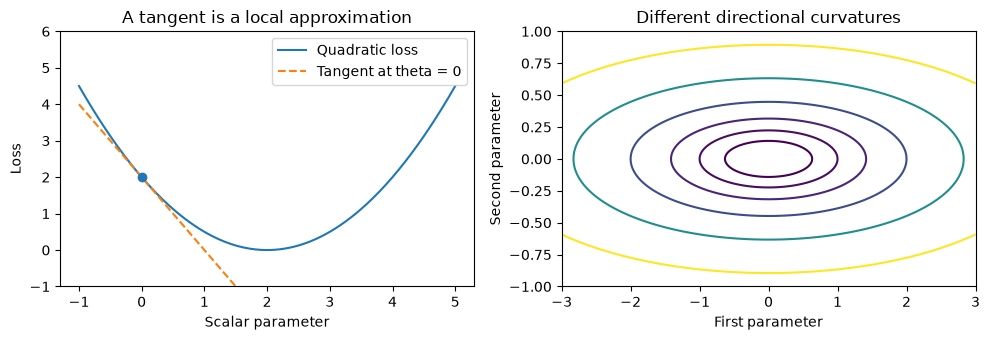

In [6]:
import numpy as np
import matplotlib.pyplot as plt

demo_theta = np.linspace(-1.0, 5.0, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(demo_theta, 0.5 * (demo_theta - 2.0) ** 2, label="Quadratic loss")
axes[0].plot(demo_theta, 2.0 - 2.0 * demo_theta, "--", label="Tangent at theta = 0")
axes[0].scatter([0], [2], zorder=3)
axes[0].set(xlabel="Scalar parameter", ylabel="Loss", ylim=(-1, 6), title="A tangent is a local approximation")
axes[0].legend()
demo_u, demo_v = np.meshgrid(np.linspace(-3, 3, 160), np.linspace(-1, 1, 160))
axes[1].contour(demo_u, demo_v, 0.5 * (demo_u**2 + 20 * demo_v**2), levels=[0.2, 0.5, 1, 2, 4, 8])
axes[1].set(xlabel="First parameter", ylabel="Second parameter", title="Different directional curvatures")
fig.tight_layout()
plt.show()

The next demonstration samples from four **fixed gradient values**, not a training run. All estimates are formed at one imagined parameter state. Drawing four times with replacement can repeat an example, so its mean can still differ from the exact full-data gradient.

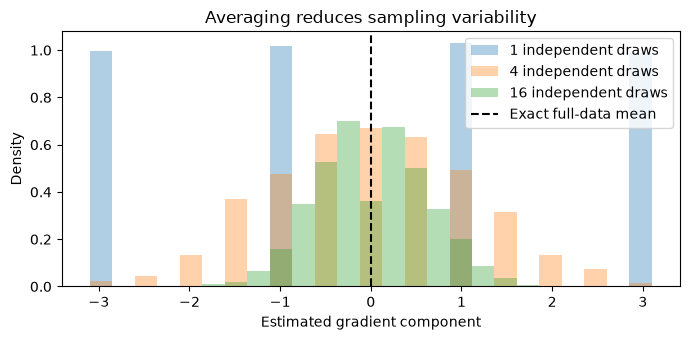

In [7]:
demo_rng = np.random.default_rng(202)
demo_gradients = np.array([-3.0, -1.0, 1.0, 3.0])
fig, ax = plt.subplots(figsize=(7, 3.5))
for demo_size in (1, 4, 16):
    demo_estimates = demo_rng.choice(demo_gradients, size=(2000, demo_size), replace=True).mean(axis=1)
    ax.hist(demo_estimates, bins=np.linspace(-3.1, 3.1, 26), density=True, alpha=0.35, label=f"{demo_size} independent draws")
ax.axvline(demo_gradients.mean(), color="black", linestyle="--", label="Exact full-data mean")
ax.set(xlabel="Estimated gradient component", ylabel="Density", title="Averaging reduces sampling variability")
ax.legend()
fig.tight_layout()
plt.show()

### Exercise 2.13 — Explore stability and oscillation

**Type:** Experimental · **Answer:** Code

Run your batch optimizer on quadratics with at least two curvatures and several rates spanning the derived boundary. Plot loss and parameter error against update count. Include rates exactly at and beyond the boundary.

**Expected outcome:** Plots with initial values, curvature, learning rates, and the distinction between shrinking oscillation and growing error clearly documented.

In [ ]:
# Your code for Exercise 2.13.
# TODO: implement the task above and record the requested checks or plots.

The following data have very different feature scales. The deterministic target rule is used only to create a study dataset. Independent Gaussian noise prevents an exact fit; no fitting routine is provided.

In [9]:
demo_data_rng = np.random.default_rng(203)
demo_X = demo_data_rng.normal(size=(90, 2)) * np.array([1.0, 1000.0])
demo_y = 1.0 + 2.0 * demo_X[:, 0] - 0.003 * demo_X[:, 1] + demo_data_rng.normal(0.0, 0.2, 90)
demo_order = demo_data_rng.permutation(90)
demo_train_ids, demo_validation_ids = demo_order[:65], demo_order[65:]
print("Training and validation sizes:", len(demo_train_ids), len(demo_validation_ids))
print("Training feature standard deviations:", demo_X[demo_train_ids].std(axis=0))

Training and validation sizes: 65 25
Training feature standard deviations: [9.14183930e-01 9.63434348e+02]


### Exercise 2.14 — Compare work and feature scales

**Type:** Experimental · **Answer:** Code

Use the supplied split with your regression implementation. Compare batch, stochastic, and mini-batch training on raw and training-standardized features. Tune rates using training/validation behavior, record at least three seeds for stochastic order, and plot full training loss against examples processed as well as against updates.

**Expected outcome:** A documented, reproducible comparison with equal data-pass budgets. Report instability when it occurs and keep scaling statistics fixed across validation evaluations.

In [ ]:
# Your code for Exercise 2.14.
# TODO: implement the task above and record the requested checks or plots.

## 7. Interpretation and critical analysis

A noisy loss curve is not automatically incorrect, and a smooth curve is not automatically evidence of good generalization. Small batches can produce many cheap but noisy updates; large batches can use vectorized arithmetic efficiently while making fewer updates per pass. Wall-clock time, examples processed, and update count answer different questions. Report which resource is controlled.

With a constant stochastic learning rate, noise can keep parameters fluctuating near a minimum. Decreasing the rate can reduce this effect at the cost of slower movement. Data order, conditioning, and the chosen loss convention also matter. Rescaling an objective from half-MSE to MSE doubles its gradient, so copying an unchanged rate doubles each gradient-based step.

### Exercise 2.15 — Challenge an unfair optimizer comparison

**Type:** Critical · **Answer:** Markdown

A report claims mini-batches are superior because they have lower loss after 100 updates than full-batch training. Identify missing information that could reverse the conclusion. Design a comparison protocol and state which result would still be specific to the chosen dataset.

**Expected outcome:** A critique covering computational work, learning-rate selection, randomness, and held-out evaluation.

**Your response to Exercise 2.15**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 8. Review questions and knowledge checks

### Exercise 2.16 — Describe a complete update

**Type:** Conceptual · **Answer:** Markdown

Describe where a batch gradient is evaluated, how a mini-batch estimate is averaged, when parameters change, and when full training loss is measured. Explain why averaging gradients computed before any updates is different from averaging parameters after sequential updates.

**Expected outcome:** A precise sequence in your own words that would prevent accidental mixing of parameter states.

**Your response to Exercise 2.16**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

### Exercise 2.17 — Connect feature scaling to parameters

**Type:** Mathematical · **Answer:** Markdown

Starting from standardized predictions $b'+\sum_jw'_j(x_j-\mu_j)/s_j$, derive weights and intercept in the original units. Explain the assumptions under which this conversion is valid.

**Expected outcome:** An expansion and coefficient comparison, including a treatment of zero-scale features.

**Your response to Exercise 2.17**

_Write your answer here. Use Markdown and LaTeX formatting for calculations and derivations._

## 9. Summary and next learning steps

Gradient descent follows local slope information, with curvature controlling whether a finite step is useful. Batch, stochastic, and mini-batch methods differ in the gradient information and work used per update. Unbiased gradient estimates require a sampling statement; they do not imply monotone sampled trajectories. Scaling, averaging, randomness, and monitoring are parts of an experiment's definition.

Before moving on, verify one update by hand, check that a final short batch is retained, and compare full losses at consistent parameter states. You now have the optimization tools needed for [Logistic Regression](logistic-regression.ipynb), where the output becomes a probability and the objective comes from a probabilistic model.